# SML 301

## Session 15: Image Processing

* review of neural network calculations
* image processing
* data augmentation

## Prep

* Installing the packages (above) might take a few minutes
* Hereafter, you are advised to *connect* to a T4 GPU runtime (upper-right corner)

In [ ]:
import cv2 #Open Source Computer Vision library
import json
import numpy as np
import pandas as pd
import pytorch_lightning as pl
import sympy
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
import urllib.request

from matplotlib import pyplot as plt
#from palmerpenguins import load_penguins
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sympy import isprime
from torch.utils.data import TensorDataset, DataLoader
from torchvision import transforms  # Use pretrained PyTorch models
from torchvision.models import resnet18, ResNet18_Weights

In [3]:
# seed function for reproducibility
def random_seed(seed_value):
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    #random.seed(seed_value)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

lr = 0.01 #learning rate

# Image Processing

Chapter 8 of *Machine Learning with Python Cookbook* by Gallatin and Albon

## Prep

* upload an image file into your Colab session (mentally note where it has been stored)

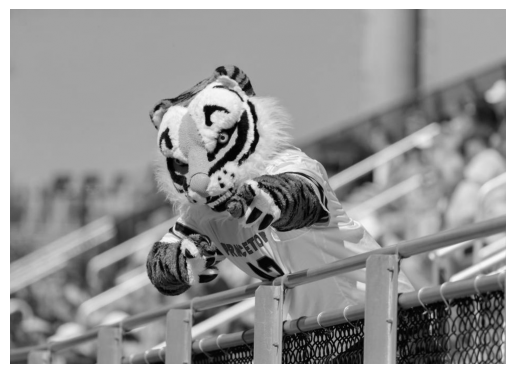

In [17]:
# Load image as grayscale.
# Intensity values range from black = 0 to white = 255.
image = cv2.imread("/content/princeton_tiger.png", cv2.IMREAD_GRAYSCALE)

# Show image
plt.imshow(image, cmap="gray")
plt.axis("off")
plt.show()

<class 'numpy.ndarray'>
(679, 950)


array([[149, 149, 150, ..., 169, 169, 169],
       [149, 149, 150, ..., 169, 169, 169],
       [149, 149, 150, ..., 169, 169, 169],
       ...,
       [ 58,  58,  59, ..., 149, 157, 158],
       [ 55,  55,  56, ..., 148, 155, 158],
       [ 58,  58,  59, ..., 150, 156, 157]], dtype=uint8)
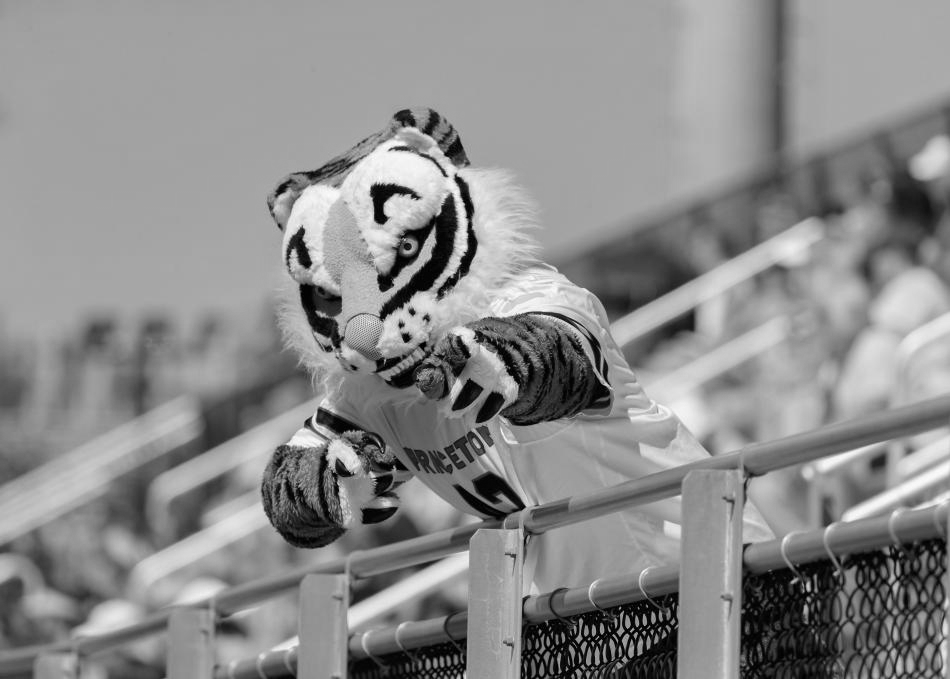

In [20]:
# Show data type
print(type(image))

# Get resolution
print(image.shape)

# Show image data
image



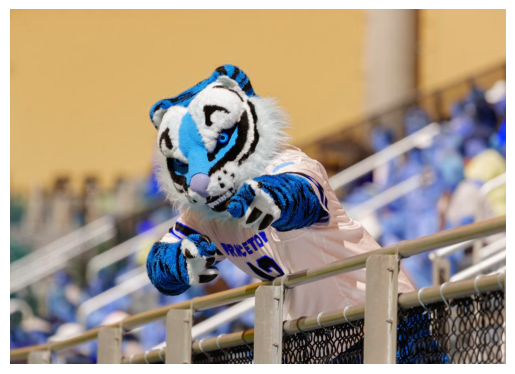

In [24]:
# Load image in BGR (blue, green, red) colors
image_bgr = cv2.imread("/content/princeton_tiger.png", cv2.IMREAD_COLOR)

# Show pixel
image_bgr[0, 0]

# Show image
plt.imshow(image_bgr)
plt.axis("off")
plt.show()

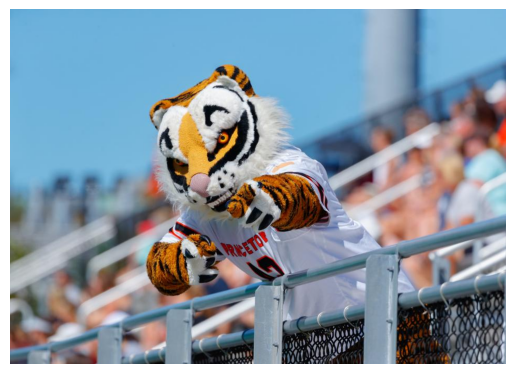

In [25]:
# OpenCV uses BGR as default.
# Matplotlib uses RGB as default.
# In order to show the image in Matplotlib, we should convert it to RGB.
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

# Show image
plt.imshow(image_rgb), plt.axis("off")
plt.show()

## Saving Images

In [28]:
# Save image.
# If the image already exists, imwrite() overwrites it.
cv2.imwrite("/content/princeton_tiger_rgb.png", image_rgb)

True

## Resizing Images

(679, 950)


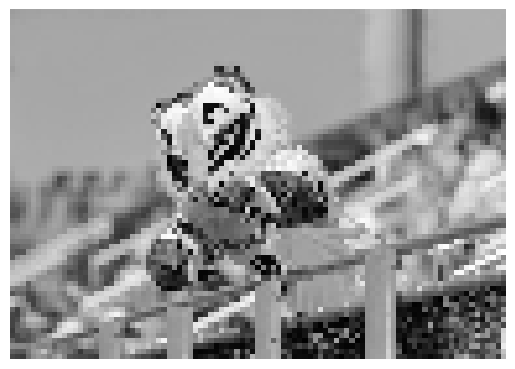

In [33]:
# Get resolution
print(image.shape)

# Resize image
image_smaller = cv2.resize(image, (image.shape[1] // 10, image.shape[0] // 10))
image_smaller.shape

# View image
plt.imshow(image_smaller, cmap="gray"), plt.axis("off")
plt.show()

## Cropping Images

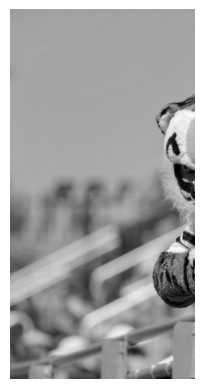

(<matplotlib.image.AxesImage at 0x78ea0c0cb6b0>,
 (np.float64(-0.5), np.float64(338.5), np.float64(678.5), np.float64(-0.5)),
 None)

In [35]:
# Select first half of the columns and all rows
image_cropped = image[:, :image.shape[0] // 2]
image_cropped.shape

# Show image
plt.imshow(image_cropped, cmap="gray"), plt.axis("off"), plt.show()

## Blurring Images

See also:
Image Kernels Explained Visually
https://setosa.io/ev/image-kernels/

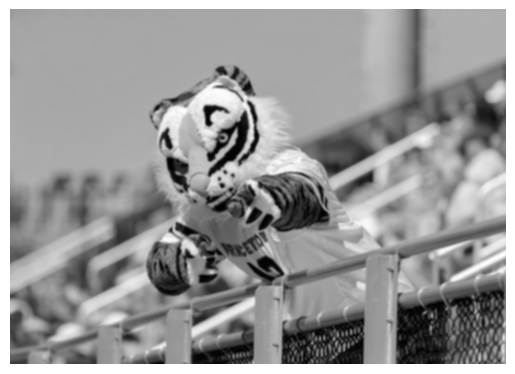

In [36]:
# Blur image with the kernel size of (5, 5)
image_blurry = cv2.blur(image, (5, 5))

# Show image
plt.imshow(image_blurry, cmap="gray"), plt.axis("off")
plt.show()

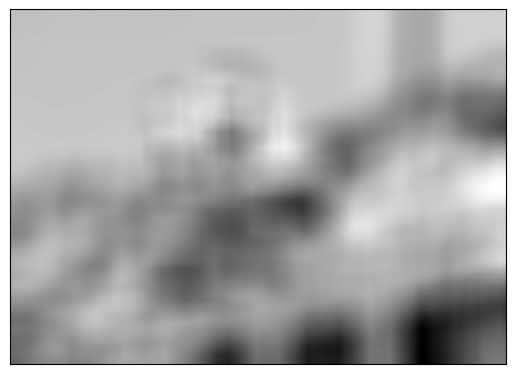

In [37]:
# Blur image with the kernel size of (10, 10)
image_very_blurry = cv2.blur(image, (100, 100))

# Show image
plt.imshow(image_very_blurry, cmap="gray"), plt.xticks([]), plt.yticks([])
plt.show()

## Sharpening Images

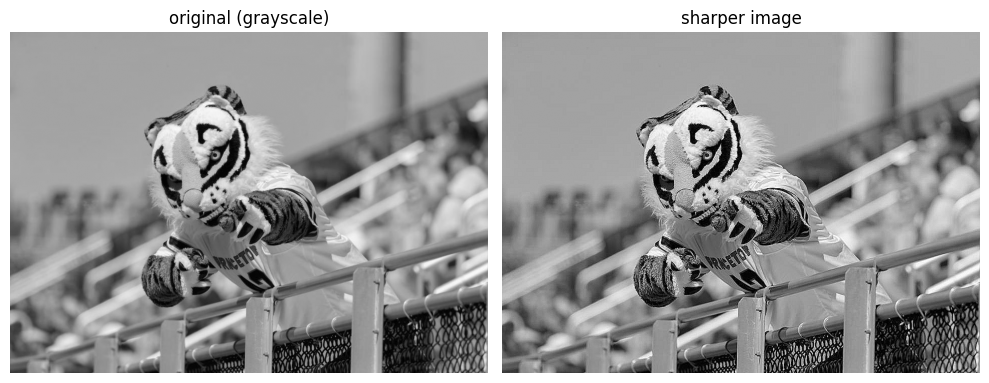

In [41]:
# Create kernel
kernel = np.array(
    [[ 0, -1,  0],
     [-1,  5, -1],
     [ 0, -1,  0]]
)

# Sharpen image
image_sharp = cv2.filter2D(image, -1, kernel)

# Show images
# Create a figure and a 1x2 grid of subplots (1 row, 2 columns)
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image, cmap = "gray")
axes[0].set_title('original (grayscale)')
axes[0].axis('off')  # Turn off axis labels and ticks
axes[1].imshow(image_sharp, cmap = "gray")
axes[1].set_title('sharper image')
axes[1].axis('off')  # Turn off axis labels and ticks
plt.tight_layout()
plt.show()

## Enhancing Contrast

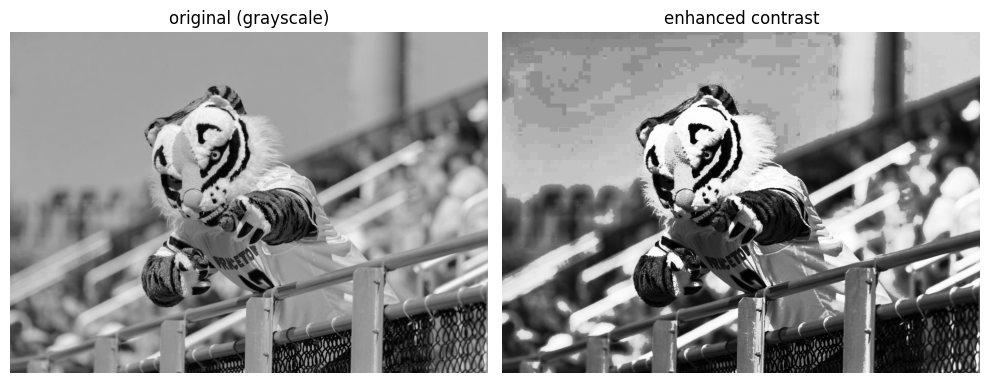

In [43]:
# grayscale images
image_enhanced = cv2.equalizeHist(image)

# Show images
# Create a figure and a 1x2 grid of subplots (1 row, 2 columns)
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image, cmap = "gray")
axes[0].set_title('original (grayscale)')
axes[0].axis('off')  # Turn off axis labels and ticks
axes[1].imshow(image_enhanced, cmap = "gray")
axes[1].set_title('enhanced contrast')
axes[1].axis('off')  # Turn off axis labels and ticks
plt.tight_layout()
plt.show()

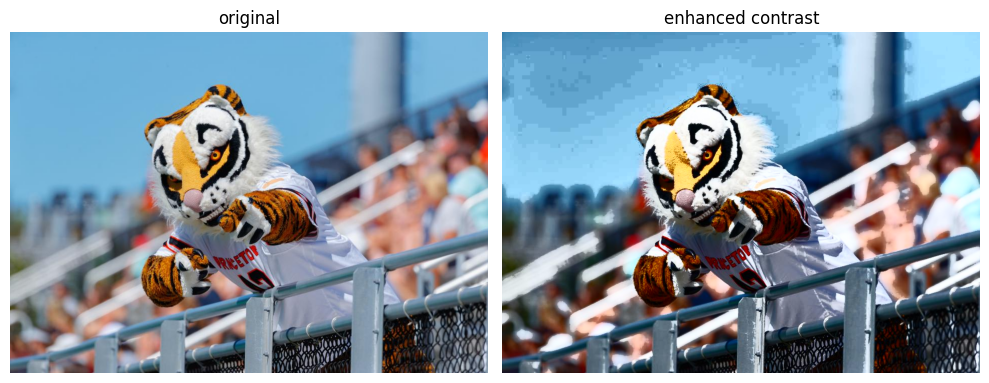

In [44]:
# For color images:
# - Convert to YUV (Y = luma, or brightness, U, V = colors).
# ->
# - equalizeHist
# ->
# - Convert to BGR or RGB.

# Convert to YUV
image_yuv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2YUV)

# Apply histogram equalization
image_yuv[:, :, 0] = cv2.equalizeHist(image_yuv[:, :, 0])

# Convert to RGB
image_rgb_enhanced = cv2.cvtColor(image_yuv, cv2.COLOR_YUV2RGB)

# Show images
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image_rgb)
axes[0].set_title('original')
axes[0].axis('off')  # Turn off axis labels and ticks
axes[1].imshow(image_rgb_enhanced)
axes[1].set_title('enhanced contrast')
axes[1].axis('off')  # Turn off axis labels and ticks
plt.tight_layout()
plt.show()


# Isolating Colors

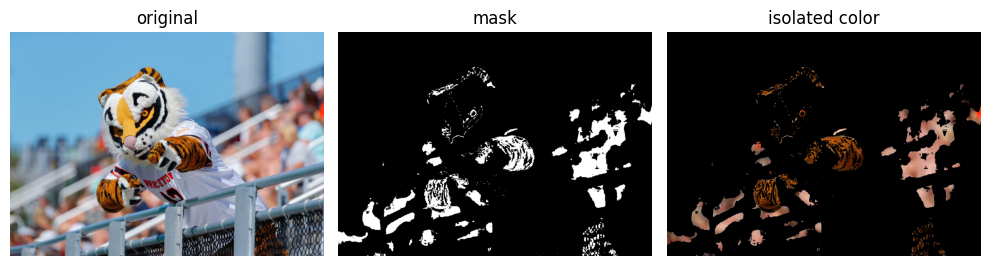

In [53]:
# Convert BGR to HSV
image_hsv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)

# Define range of blue values in HSV
# lower_bound = np.array([50, 100, 50]) #blues
# upper_bound = np.array([130, 255, 255]) #blues
# https://stackoverflow.com/questions/10948589/choosing-the-correct-upper-and-lower-hsv-boundaries-for-color-detection-withcv
lower_bound = np.array([5, 50, 50]) #oranges
upper_bound = np.array([15, 255, 255]) #oranges

# Create mask
mask = cv2.inRange(image_hsv, lower_bound, upper_bound)

# Mask image
image_bgr_masked = cv2.bitwise_and(image_bgr, image_bgr, mask=mask)

# Convert BGR to RGB
image_rgb_iso_orange = cv2.cvtColor(image_bgr_masked, cv2.COLOR_BGR2RGB)

# Show images
fig, axes = plt.subplots(1, 3, figsize=(10, 5))
axes[0].imshow(image_rgb)
axes[0].set_title('original')
axes[0].axis('off')  # Turn off axis labels and ticks
axes[1].imshow(mask, cmap = "gray")
axes[1].set_title('mask')
axes[1].axis('off')  # Turn off axis labels and ticks
axes[2].imshow(image_rgb_iso_orange)
axes[2].set_title('isolated color')
axes[2].axis('off')  # Turn off axis labels and ticks
plt.tight_layout()
plt.show()

# Binarizing Images

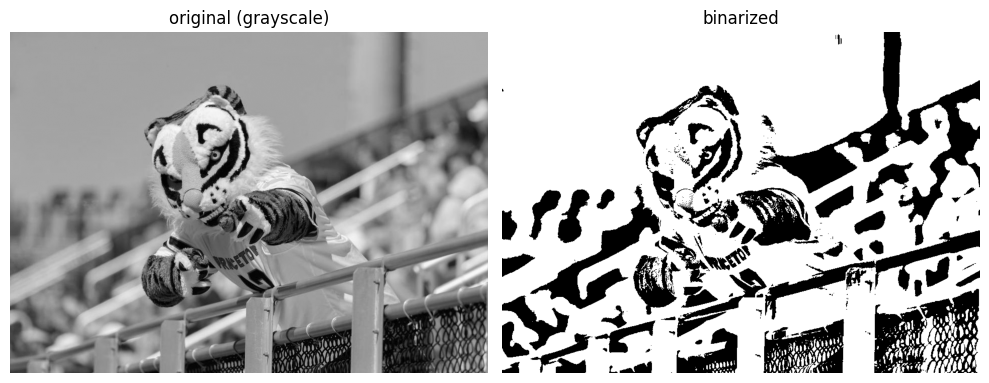

In [57]:
# Apply adaptive thresholding
max_output_value = 255  # the maximum intensity of the output pixel intensities
neighborhood_size = 99  # the size of the neighborhood used to determine a pixel's threshold
subtract_from_mean = 10  # a constant subtracted from the calculated threshold -> fine-tuning

# Apply cv2.ADAPTIVE_THRESH_MEAN_C:
# the mean of the neighboring pixels
image_mean_threshold = cv2.adaptiveThreshold(
    image,
    max_output_value,
    cv2.ADAPTIVE_THRESH_MEAN_C,
    cv2.THRESH_BINARY,
    neighborhood_size,
    subtract_from_mean,
)

# Show images
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image, cmap = "gray")
axes[0].set_title('original (grayscale)')
axes[0].axis('off')  # Turn off axis labels and ticks
axes[1].imshow(image_mean_threshold, cmap = "gray")
axes[1].set_title('binarized')
axes[1].axis('off')  # Turn off axis labels and ticks
plt.tight_layout()
plt.show()

## Removing Background
### TODO: find better code from a different library

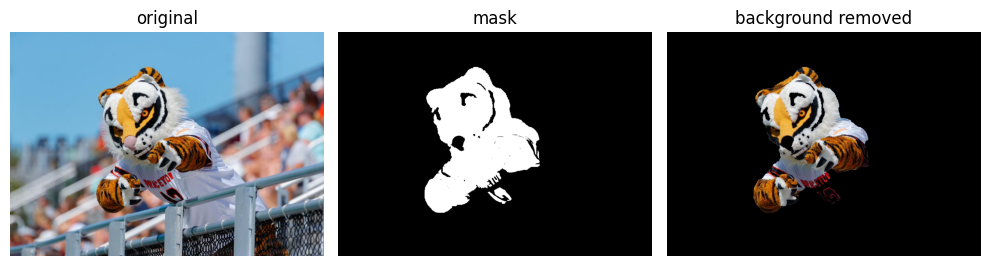

In [59]:
# Rectangle values: start x, start y, width, height
rectangle = (225, 75, 450, 490)

# Create initial mask
mask = np.zeros(image_rgb.shape[:2], np.uint8)

# Create temporary arrays used by grabCut
bgdModel = np.zeros((1, 65), np.float64)
fgdModel = np.zeros((1, 65), np.float64)

# Apply grabCut
cv2.grabCut(
    image_rgb,  # image
    mask,
    rectangle,
    bgdModel,  # temporary array for background
    fgdModel,  # temporary array for foreground
    5,  # number of iterations
    cv2.GC_INIT_WITH_RECT,  # Initiative with rectangle
)

# Create new mask where sure (mask == 0) and likely (mask == 2) backgrounds set to 0, otherwise 1
new_mask = np.where((mask == 0) | (mask == 2), 0, 1).astype('uint8')

# matrix
image_rgb_nobg = image_rgb * new_mask[:, :, np.newaxis]

# Show images
fig, axes = plt.subplots(1, 3, figsize=(10, 5))
axes[0].imshow(image_rgb)
axes[0].set_title('original')
axes[0].axis('off')  # Turn off axis labels and ticks
axes[1].imshow(new_mask, cmap = "gray")
axes[1].set_title('mask')
axes[1].axis('off')  # Turn off axis labels and ticks
axes[2].imshow(image_rgb_nobg)
axes[2].set_title('background removed')
axes[2].axis('off')  # Turn off axis labels and ticks
plt.tight_layout()
plt.show()

## Edge Detection

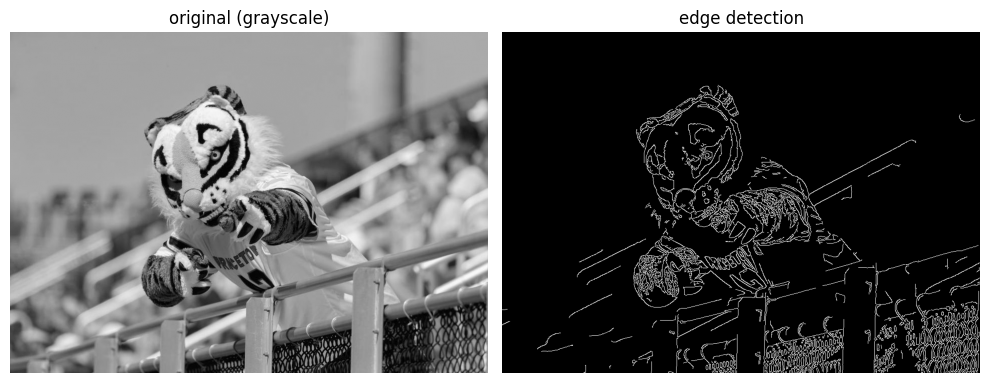

In [61]:
# Calculate median intensity
median_intensity = np.median(image)

# Set thresholds to be one standard deviation above and below median intensity
lower_threshold = int(max(0, (1.0 - 0.33) * median_intensity))
upper_threshold = int(min(255, (1.0 + 0.33) * median_intensity))

# Apply Canny edge detector
image_canny = cv2.Canny(image, lower_threshold, upper_threshold)

# Show images
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image, cmap = "gray")
axes[0].set_title('original (grayscale)')
axes[0].axis('off')  # Turn off axis labels and ticks
axes[1].imshow(image_canny, cmap = "gray")
axes[1].set_title('edge detection')
axes[1].axis('off')  # Turn off axis labels and ticks
plt.tight_layout()
plt.show()

# Creating Features for Machine Learning

# Flatten

In [62]:
# Resize image to 10 pixels by 10 pixels
image_10x10 = cv2.resize(image, (10, 10))

# Convert image data to one-dimensional vector
image_10x10.flatten()
image_10x10.flatten().shape

(100,)

## Band Histograms

(679, 950, 3)


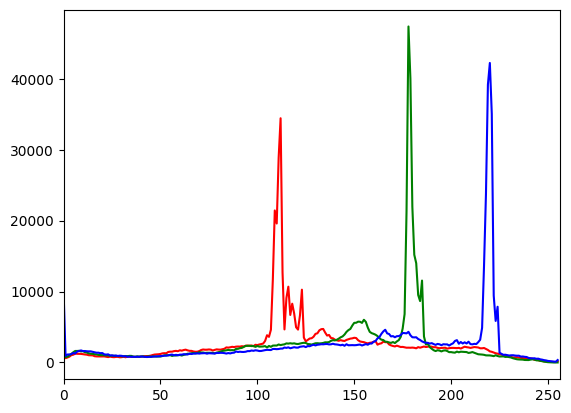

256*3 features


In [64]:
print(image_rgb.shape)

# Create a list for feature values
features = []

# Calculate histogram or each channel and add to feature value list
for i, channel in enumerate(["r", "g", "b"]):  # 0 = red, 1 = green, 2 = blue
    histogram = cv2.calcHist(
        [image_rgb],  # image
        [i],  # index of channel
        None,  # no mask
        [256],  # histogram size
        [0, 256])  # range
    # The x-axis represents the 256 possible channel values,
    # and the y-axis represents the number of times a particular channel value
    # appears across all pixels in an image
    plt.plot(histogram, color=channel)
    plt.xlim([0, 256])
    features.extend(histogram)

# Show plot
plt.show()
print("256*3 features")

# Transfer Learning

## TODO: describe transfer learning and ResNet

In [71]:
# Convert to PyTorch data type
convert_tensor = transforms.ToTensor()
pytorch_image = convert_tensor(image_rgb)

# Load the pretrained model
model = models.resnet18(weights=ResNet18_Weights.DEFAULT)

# Select the specific layer of the model we want output from
layer = model._modules.get('avgpool')

# Set model to evaluation mode
model.eval()

# Infer the embedding with the no_grad option
with torch.no_grad():
    embedding_pytorch = model(pytorch_image.unsqueeze(0))

embedding_pytorch.shape

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 201MB/s]


torch.Size([1, 1000])

# Image Classification

In [74]:
# Get imagenet classes
url = "https://raw.githubusercontent.com/raghakot/keras-vis/master/resources/imagenet_class_index.json"
with urllib.request.urlopen(url) as src:
    imagenet_class_index = json.load(src)

In [75]:
# Instantiate pretrained model
model = resnet18(weights=ResNet18_Weights.DEFAULT)

In [77]:
# Convert to pytorch data type
convert_tensor = transforms.ToTensor()
pytorch_image = convert_tensor(image_rgb)

# Set model to evaluation mode
model.eval()

# Make a prediction
prediction = model(pytorch_image.unsqueeze(0))

# Get the index of the highest predicted probability
_, index = torch.max(prediction, 1)

# Convert that to a percentage value
percentage = torch.nn.functional.softmax(prediction, dim=1)[0] * 100

print("Class:", imagenet_class_index[str(index.tolist()[0])][1])

print(f"Max. probability: {percentage[index.tolist()[0]].item():.2f}%")

Class: paper_towel
Max. probability: 0.96%
